---

# **Week 4 - Storage and File System Forensics**

---


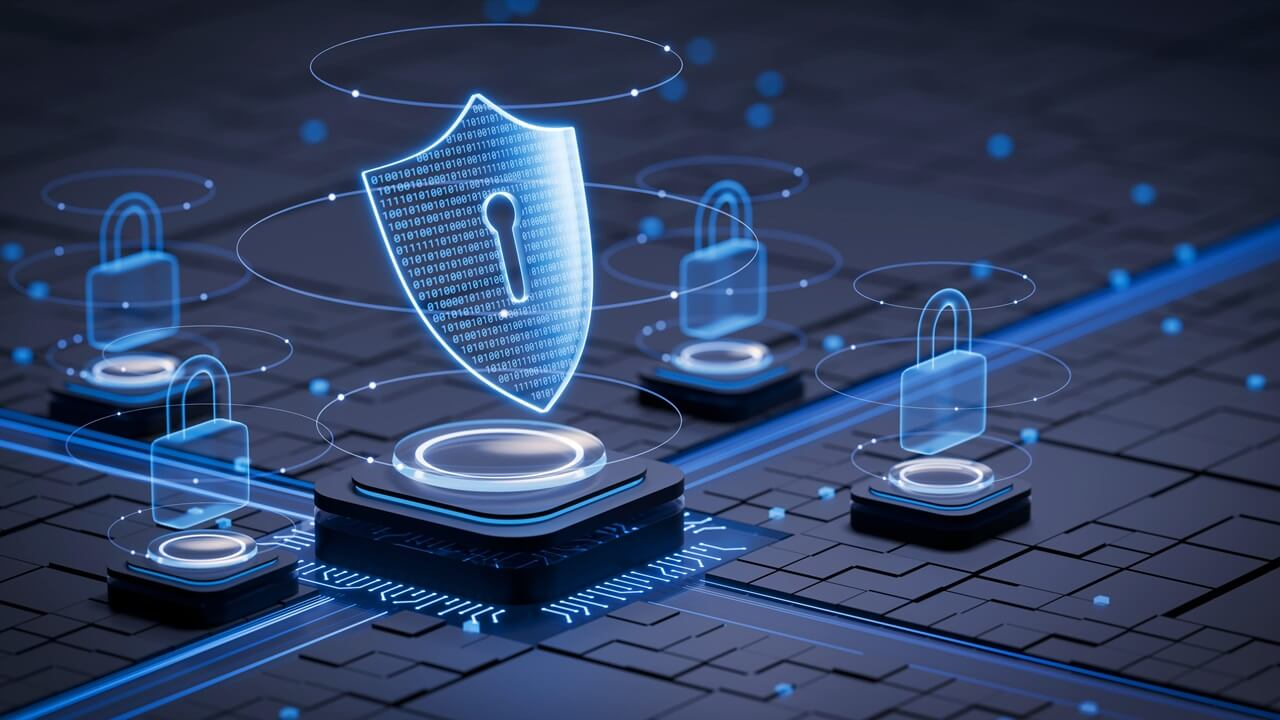


---

## 🔹 **1. Bits, Bytes, Sectors, Clusters**

**Definition:**

Storage is organized in layers: bits make bytes, bytes are grouped into sectors, and file systems often allocate space in clusters (groups of sectors).

💡 **In simple words:** *Think of a warehouse: bytes are items, sectors are small boxes, clusters are shelves the file system assigns to files.*

**Easy example:** A tiny text file may still occupy a full cluster - leftover space in that cluster can hold older residue.

| **Unit** | **Simple idea** |
| --- | --- |
| Bit | Smallest unit (0 or 1) |
| Byte | 8 bits; one text character is often one byte |
| Sector | Small fixed disk block (commonly 512 or 4096 bytes) |
| Cluster | Allocation unit made of one or more sectors |

**🧩 Small Problem:** If a tiny text file is 10 bytes, must it occupy only 10 bytes on disk?

**✅ Solved:** Often no. File systems usually allocate at least one full cluster, so unused space may remain inside that allocation.

<img src="https://www.pulsetechnology.com/hs-fs/hubfs/Cybersecurity%20Graphic.gif?width=1600&height=511&name=Cybersecurity%20Graphic.gif" width="350" alt="storage units">


---

## 🔹 **2. Allocated vs Unallocated**

**Definition:**

Allocated space is marked as in use by a file or system structure. Unallocated space is marked free and may still contain leftover bytes from earlier files.

💡 **In simple words:** *Allocated means "currently claimed." Unallocated means "marked free," not "guaranteed empty."*

**Easy example:** A deleted photo may no longer appear in the folder list, yet photo-header bytes can still sit in unallocated space until overwritten.

| **State** | **What it means** | **Forensic caution** |
| --- | --- | --- |
| Allocated | Belongs to a live file/metadata | Content is active data |
| Unallocated | Free according to the file system | May hold residual content |
| Reserved / special | System areas | Not ordinary user files |

**🧩 Small Problem:** Does "deleted" always mean the bytes are gone?

**✅ Solved:** No. Deletion often removes references or allocation marks while content remains until overwritten.


---

## 🔹 **3. File System Metadata**

**Definition:**

File system metadata is data about files: names, locations, sizes, timestamps, and allocation information.

**Typical metadata fields:**

* File name and parent folder
* Size
* Starting cluster / data location
* Created / modified / accessed timestamps (meanings vary)
* Permissions or flags (system-dependent)

💡 **In simple words:** *Metadata is the catalog card. Content is what is on the shelf. Both can matter, and both can be incomplete.*

**Easy example:** A document Author field saying Ali is a clue to check, not automatic proof Ali wrote or leaked it.

<img src="https://media0.giphy.com/media/v1.Y2lkPTc5MGI3NjExb2NkZ2kwa25sdHU2bmg1YWd2ZDI4b2kzY3QwMWI0bmFmY25uOWJmayZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/sANGK3xBT0ipq/giphy.gif" width="350" alt="file system metadata">


---

## 🔹 **4. Timestamp Caveats**

**Definition:**

Timestamps are recorded times associated with a file or event. Their meaning depends on the file system, the application, and clock settings.

**Easy example:** A document Author field saying Ali is a clue to check, not automatic proof Ali wrote or leaked it.

| **Caveat** | **Why it matters** |
| --- | --- |
| Different clocks | Devices may not share one time zone or sync state. |
| Different meanings | Modified time is not always "user edited the document." |
| Copy effects | Copying can create new timestamps on the destination. |
| Missing context | A time alone rarely proves who acted. |

**🧩 Small Problem:** File modified at 14:05. Does that prove a person edited it at 14:05?

**✅ Solved:** No. Many processes update modified times. Seek corroborating records.

<img src="https://items.epicpxls.com/uploads/photo/853e204550cf68de8789b0c4d7e698b0.gif" width="350" alt="timestamp caveats">


---

## 🔹 **5. Slack Space (Simple View)**

**Definition:**

Slack is unused space that can remain at the end of an allocated cluster after a file's real content ends.

💡 **In simple words:** *If a file needs 10 bytes but the cluster is larger, the leftover area may still hold older residue.*

**Easy example:** In a simple campus case, use one record for "Slack Space (Simple View)" and say what it supports versus what still needs another source.

| **Idea** | **Student takeaway** |
| --- | --- |
| File size | Logical length reported by the file system |
| Allocated size | Space reserved in clusters |
| Slack | Gap between file size and end of allocation |

**🧩 Small Problem:** Is every slack byte always meaningful evidence?

**✅ Solved:** No. It may be old residue, zeros, or unrelated leftovers. Interpret carefully.


---

## 🔹 **6. Path vs Content**

**Definition:**

A path is the name and location of a file. Content is the byte payload stored for that file.

💡 **In simple words:** *The label on the box is the path. What is inside the box is the content. Labels can be wrong, reused, or missing.*

**Easy example:** In a simple campus case, use one record for "Path vs Content" and say what it supports versus what still needs another source.

| **Observation** | **Supports** | **Does not alone prove** |
| --- | --- | --- |
| Path `Notes/answers.txt` exists | A name/location existed | That the user authored the text |
| Content contains "Q3 answer" | Those bytes are present | Intent or exam misconduct |
| Path deleted, content in unallocated | Residual bytes may remain | Exact deletion time/actor |

<img src="https://media1.giphy.com/media/v1.Y2lkPTc5MGI3NjExNjgxaTJ6eTEzYmYxYWsxZHBjYmxqenprcnFodG8zazRweTV4c2t4NiZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9cw/9Xw21tq79NuPeRJ3OE/giphy.gif" width="350" alt="path versus content">


---

## 🔹 **7. Storage Scenario - Tiny Training Volume**

**Fictional mini-volume:** A teaching disk has 8 clusters. Some hold live files, some are free but still contain leftover text from an old note.

**Questions an examiner asks:**

1. Which clusters are allocated right now?
2. Which file names point to which starting clusters?
3. Does unallocated space still contain readable residue?
4. What can we not conclude from residue alone?

**🧩 Small Problem:** Residue text says "password draft." Does that prove current credential use?

**✅ Solved:** No. It shows residual bytes. Linking them to current use needs more context.


---

## 🔹 **8. What File Systems Give Examiners**

| **Artifact class** | **Helps answer** |
| --- | --- |
| Directory / name records | What names existed and where |
| Allocation map | Which clusters are in use now |
| Timestamps | When the system recorded certain events |
| Unallocated areas | Whether residue may remain |

💡 **In simple words:** *File systems are bookkeeping systems. They help locate data; they do not automatically explain human intent.*

**Easy example:** In a simple campus case, use one record for "What File Systems Give Examiners" and say what it supports versus what still needs another source.

**🧩 Small Problem:** If the allocation map says free, should you skip those clusters always?

**✅ Solved:** Not in an examination that cares about residue. Free can still contain prior bytes.


---

## 🔹 **9. Reporting Language for Storage Finds**

Use careful wording:

**Easy example:** In a simple campus case, use one record for "Reporting Language for Storage Finds" and say what it supports versus what still needs another source.

* **Observation:** "Unallocated cluster 3 contains the ASCII marker `OLD:` followed by text."
* **Limit:** "The examination does not establish the author or deletion time from this residue alone."
* **Next sources:** "Compare with cloud version history and account audit logs."

| **Avoid** | **Prefer** |
| --- | --- |
| "User hid answers here" | "Residual text matching keyword X is present at cluster Y" |
| "Deleted at 14:05" | "No deletion time is available from this toy map" |

✅ **Activity: Rewrite "Cluster 6 proves cheating" into an observation plus a limit.**


---

## 🔹 **10. Storage Pitfalls**

**Easy example:** In a simple campus case, use one record for "Storage Pitfalls" and say what it supports versus what still needs another source.

| **Pitfall** | **Correction** |
| --- | --- |
| Treating path as proof of authorship | Seek content and account context |
| Ignoring clock issues | Normalize and corroborate times |
| Assuming free means empty | Search residue when justified |
| Over-reading slack | Report presence carefully; avoid stories |

**🧩 Small Problem:** A path is `cheat_sheet.txt`. Does the name prove cheating?

**✅ Solved:** No. Names can be jokes, defaults, or misleading. Examine content and context.


---

## 🔹 **11. From Clusters to Questions**

| **Storage observation** | **Investigative follow-up** |
| --- | --- |
| Live file `notes.txt` spans clusters 1-2 | Read content; check related logs |
| Cluster 3 free but contains `OLD:` text | Record residue; do not invent an author |
| Timestamp on `schedule.csv` | Corroborate with another source before relying on it |

💡 **In simple words:** *Storage facts open questions. They rarely close a case by themselves.*

**Easy example:** A tiny text file may still occupy a full cluster - leftover space in that cluster can hold older residue.


---

## 🔹 **12. Mini Check Before the Lab**

**Easy example:** In a simple campus case, use one record for "Mini Check Before the Lab" and say what it supports versus what still needs another source.

| **Prompt** | **Solid answer** |
| --- | --- |
| Cluster | Allocation unit grouping sectors |
| Unallocated | Marked free; may still hold old bytes |
| Metadata | Catalog facts about a file |
| Path vs content | Location/name vs payload bytes |

✅ **Exit ticket:** Define allocated space and give one reason timestamps need caution.


---

# **📋 CASE STUDY - Student Challenge**

---

## **Same Name, Different Clusters**

### **Scenario**

A training disk map shows filename `report.pdf` in a directory entry pointing to cluster 40. Unallocated clusters 88-90 contain bytes starting with a PDF header. A student concludes the deleted `report.pdf` is fully recovered.

### **Your Tasks**

1. Separate **directory metadata** from **unallocated residue**.
2. What can you claim about clusters 88-90?
3. What can you **not** claim yet?
4. Name two reasons carving/recovery might be incomplete.
5. Write a cautious one-sentence finding.

### **How to work it**

* Attempt the tasks **before** reading the model solution below.
* Label answers as observation, inference, or unknown where relevant.
* Keep claims inside the supplied records.

---


---

# **✅ CASE STUDY - Model Solution**

---

### **Same Name, Different Clusters - Worked Answer**

**1.** The directory entry describes a named object and its recorded location (cluster 40). Clusters 88-90 are unallocated residue that may relate to a PDF-like object, not automatically to that directory entry.

**2.** You can claim PDF-signature bytes exist at those unallocated offsets.

**3.** You cannot claim they are the complete original `report.pdf`, nor that they match the directory entry, without more linkage/validation.

**4.** Fragmentation; partial overwrite; missing footer; incorrect assembly.

**5.** Unallocated clusters 88-90 contain PDF-header residue; linkage to the named `report.pdf` entry is not established from the given map alone.

💡 **Reminder:** Your wording may differ. Marks (if used) should reward correct forensic reasoning, not identical sentences.

---


---

# **🐧 Kali Linux Tool Link**

---
This week connects to the Kali toolkit lab: [`Kali_Linux_DF_Toolkit.ipynb`](Kali_Linux_DF_Toolkit.ipynb).

## 🔹 **exiftool**

**Purpose:** Read and report file metadata without guessing from the file name alone.

**Why this week:** Supports Week 4 storage/metadata reasoning with a real examiner-style CLI.

**Package hint:** `libimage-exiftool-perl`

**Easy example:** Open the Kali toolkit notebook and run the **exiftool** section on the synthetic evidence pack.

## 🔹 **fls / mmls (Sleuth Kit)**

**Purpose:** List partitions and file-system entries from a disk image.

**Why this week:** Connects allocated/unallocated thinking to a classic forensic toolkit.

**Package hint:** `sleuthkit`

**Easy example:** Open the Kali toolkit notebook and run the **fls / mmls (Sleuth Kit)** section on the synthetic evidence pack.

**Reminder:** Use Kali on authorized classroom evidence only. Do not acquire personal or campus devices without approval.

---


# **LAB WEEK 4:**

---


---

# **🔍 Digital Forensics 101 - Week 4 Lab**

**Platform:** Python 3 in Jupyter Notebook or Google Colab  
**Focus:** Explore a synthetic cluster map, metadata table, and unallocated residue  
**Mode:** Hands-on work with fictional training files  
**Goal:** Practice the week's methods on synthetic evidence only.

---

## **📌 Week 4 Lab Overview**

Complete these guided practicals:

1. **Build and display a synthetic cluster allocation map**
2. **Create a file metadata table from the map**
3. **Search unallocated clusters for residual text**

### **📂 Tasks**

* Run the cells **from top to bottom**.
* Predict the result before executing each practical.
* Record one observation and one limitation per practical.
* Use only the synthetic files generated by the setup cell.

### **🛠️ Tools Used**

* Python standard library only (`pathlib`, `hashlib`, `csv`, `json`, `tempfile`, `datetime` as needed).

**Run behavior:** Setup creates a new temporary folder on every run. Later cells use that folder. The notebook does not examine your personal files.

---


## **🧰 Setup - Toy Volume in Memory**

Create an 8-cluster synthetic volume where each cluster holds a short ASCII payload. Some clusters are free but not empty.
**Easy example:** A live uploader process may exist only in RAM; restarting the PC can destroy that evidence before disk imaging helps.


In [ ]:
# Objective: Create a synthetic 8-cluster volume with allocation marks and payloads.
# Output: cluster_map.json describing allocation, owners, and cluster text.
# Interpretation: A tiny model makes allocated vs unallocated visible without real disks.
# Forensic Meaning: Real file systems are larger, but the allocation idea is the same.

from pathlib import Path
# Import tempfile for this step.
import tempfile
# Import json for this step.
import json
# Import csv for this step.
import csv

# Create a fresh temporary folder so personal files are not touched.
lab_dir = Path(tempfile.mkdtemp(prefix="digital_forensics_week4_"))

# Each cluster: payload text plus allocation flag and optional file owner.
clusters = [
    # Perform this step of the practical.
    {"id": 0, "allocated": True, "owner": "readme.txt", "data": "README: lab volume v1"},
    # Perform this step of the practical.
    {"id": 1, "allocated": True, "owner": "notes.txt", "data": "Meeting notes 10:00"},
    # Perform this step of the practical.
    {"id": 2, "allocated": True, "owner": "notes.txt", "data": "Bring USB for print"},
    # Perform this step of the practical.
    {"id": 3, "allocated": False, "owner": None, "data": "OLD: draft answers Q3"},
    # Perform this step of the practical.
    {"id": 4, "allocated": True, "owner": "schedule.csv", "data": "slot,room\nA,W08"},
    # Perform this step of the practical.
    {"id": 5, "allocated": False, "owner": None, "data": "\x00\x00unused-ish"},
    # Perform this step of the practical.
    {"id": 6, "allocated": False, "owner": None, "data": "OLD: password draft"},
    # Perform this step of the practical.
    {"id": 7, "allocated": True, "owner": "readme.txt", "data": "End of readme"},
]

# Set map_path for the next steps.
map_path = lab_dir / "cluster_map.json"
# Write synthetic training bytes/text into the file.
map_path.write_text(json.dumps(clusters, indent=2), encoding="utf-8")

# Show the result for discussion.
print("Training folder:", lab_dir)
# Show the result for discussion.
print("Clusters:", len(clusters))
# Show the result for discussion.
print("Allocated:", sum(1 for c in clusters if c["allocated"]))
# Show the result for discussion.
print("Unallocated:", sum(1 for c in clusters if not c["allocated"]))


---

## **1️⃣ Practical - Cluster Map View**

### **📂 Tasks**

1. Print each cluster's id, allocation state, and owner.
2. Count free clusters that are not empty.


In [ ]:
# Objective: Display the synthetic cluster map and count non-empty free clusters.
# Output: Table-like printout plus count of residual unallocated clusters.
# Interpretation: Free-but-not-empty clusters are where residue searches begin.
# Forensic Meaning: Unallocated does not mean forensically blank.

print(f"{'ID':>3} {'ALLOC':>6} {'OWNER':<15} DATA")
# Show the result for discussion.
print("-" * 60)
# Set residual_free for the next steps.
residual_free = 0
# Loop through each item needed for the check.
for c in clusters:
    # Set owner for the next steps.
    owner = c["owner"] or "-"
    # Treat non-null-looking payloads as residual content for this toy model.
    nonempty = bool(c["data"].replace("\x00", "").strip())
    # Branch on the condition relevant to this check.
    if (not c["allocated"]) and nonempty:
        # Perform this step of the practical.
        residual_free += 1
    # Show the result for discussion.
    print(f"{c['id']:>3} {str(c['allocated']):>6} {owner:<15} {c['data'][:28]}")

# Show the result for discussion.
print("Unallocated clusters with residual text:", residual_free)


### **✅ Interpretation**

* Allocated clusters show current live ownership in the toy map.
* Unallocated clusters may still contain readable text.
* "Free" is a bookkeeping state, not a promise of emptiness.


---

## **2️⃣ Practical - Metadata Table**

### **📂 Tasks**

1. Group allocated clusters by owner file.
2. Write `metadata_table.csv` with start cluster, cluster count, and joined size.


In [ ]:
# Objective: Build a simple metadata table from allocated clusters.
# Output: metadata_table.csv with file name, start cluster, cluster count, byte size.
# Interpretation: Metadata summarizes where live files claim space.
# Forensic Meaning: Directory-style metadata is often the first map an examiner reads.

from collections import defaultdict

# Collect cluster ids per live file owner.
owned = defaultdict(list)
# Loop through each item needed for the check.
for c in clusters:
    # Branch on the condition relevant to this check.
    if c["allocated"] and c["owner"]:
        # Store this item in the working list.
        owned[c["owner"]].append(c)

# Set meta_rows for the next steps.
meta_rows = []
# Loop through each item needed for the check.
for name, parts in sorted(owned.items()):
    # Sort records into a stable order for review.
    parts = sorted(parts, key=lambda x: x["id"])
    # Toy size = sum of payload lengths (not a real on-disk size formula).
    size = sum(len(p["data"]) for p in parts)
    # Store this item in the working list.
    meta_rows.append(
        # Perform this step of the practical.
        {
            # Perform this step of the practical.
            "file_name": name,
            # Perform this step of the practical.
            "start_cluster": parts[0]["id"],
            # Perform this step of the practical.
            "cluster_count": len(parts),
            # Perform this step of the practical.
            "logical_size": size,
        }
    )

# Set meta_path for the next steps.
meta_path = lab_dir / "metadata_table.csv"
# Open a file/context safely for this step.
with meta_path.open("w", newline="", encoding="utf-8") as f:
    # Set writer for the next steps.
    writer = csv.DictWriter(f, fieldnames=["file_name", "start_cluster", "cluster_count", "logical_size"])
    # Perform this step of the practical.
    writer.writeheader()
    # Perform this step of the practical.
    writer.writerows(meta_rows)

# Loop through each item needed for the check.
for row in meta_rows:
    # Show the result for discussion.
    print(row)


### **✅ Interpretation**

* Metadata rows summarize live files: name, start cluster, count, size.
* This table does not list residue in free clusters.
* Path/name facts and content facts are recorded separately on purpose.


---

## **3️⃣ Practical - Unallocated Residue Search**

### **📂 Tasks**

1. Scan unallocated clusters for the keyword `OLD:`.
2. Report cluster ids and snippets only (no guilt claims).


In [ ]:
# Objective: Search unallocated clusters for residual keyword markers.
# Output: List of hits with cluster id and short snippet.
# Interpretation: Hits show residual bytes, not authorship or intent.
# Forensic Meaning: Residue supports presence of prior content, not a full story by itself.

keyword = "OLD:"
# Set hits for the next steps.
hits = []
# Loop through each item needed for the check.
for c in clusters:
    # Branch on the condition relevant to this check.
    if c["allocated"]:
        # Perform this step of the practical.
        continue
    # Branch on the condition relevant to this check.
    if keyword in c["data"]:
        # Store this item in the working list.
        hits.append({"cluster_id": c["id"], "snippet": c["data"][:40]})

# Set hits_path for the next steps.
hits_path = lab_dir / "residue_hits.json"
# Write synthetic training bytes/text into the file.
hits_path.write_text(json.dumps(hits, indent=2), encoding="utf-8")

# Show the result for discussion.
print("Residue hits:", len(hits))
# Loop through each item needed for the check.
for h in hits:
    # Show the result for discussion.
    print(f"Cluster {h['cluster_id']}: {h['snippet']}")


### **✅ Interpretation**

* Keyword hits show residual bytes in free clusters.
* Hits do not identify an author, time of deletion, or intent.
* Report observation plus limits before suggesting next sources.


---

## **🧾 Final Findings Cell**


In [ ]:
# Objective: Write cautious findings about allocated files and unallocated residue.
# Output: week4_findings.txt with file counts and residue hit counts.
# Interpretation: Separate live metadata observations from residual-byte observations.
# Forensic Meaning: Storage analysis reports presence and location limits, not motive.

lines = [
    # Perform this step of the practical.
    "Week 4 findings (synthetic toy volume)",
    # Perform this step of the practical.
    f"Live files in metadata table: {len(meta_rows)}",
    # Perform this step of the practical.
    f"Unallocated residue hits for '{keyword}': {len(hits)}",
    # Perform this step of the practical.
    "Observation: some free clusters still contain prior text markers.",
    # Perform this step of the practical.
    "Limit: this model cannot establish who created the residue or when it became free.",
    # Perform this step of the practical.
    "Conclusion: allocated map and residue search completed; no misconduct finding.",
]
# Set findings_path for the next steps.
findings_path = lab_dir / "week4_findings.txt"
# Write synthetic training bytes/text into the file.
findings_path.write_text("\n".join(lines) + "\n", encoding="utf-8")
# Show the result for discussion.
print(findings_path.read_text(encoding="utf-8"))


---

# **Summary and Reinforcement** 📝🔍

---

## 🔹 **Core Concepts**

**Easy example:** In a simple campus case, use one record for "Core Concepts" and say what it supports versus what still needs another source.

* **Byte / sector / cluster** → Layered storage units.
* **Allocated** → Marked in use.
* **Unallocated** → Marked free; may still hold residue.
* **Metadata** → Catalog information about files.
* **Timestamp caveat** → Time fields need context.
* **Slack** → Unused space inside an allocation.
* **Path vs content** → Name/location vs payload bytes.

---
## 🔹 **Quick Quiz**

**Easy example:** In a simple campus case, use one record for "Quick Quiz" and say what it supports versus what still needs another source.

**Q1.** Unallocated space is always empty.
* A) True
* B) False ✅

**Q2.** A cluster is:
* A) A user password
* B) A file system allocation unit ✅
* C) A courtroom verdict

**Q3.** Modified time alone proves a person edited a file.
* A) True
* B) False ✅

**Q4.** Path and content:
* ✅ Can disagree; both need careful interpretation.

**Q5.** Slack is:
* ✅ Unused space that may remain in an allocated cluster.

---

✅ **Exit Ticket:** One storage unit definition and one thing residue cannot prove alone.


---

# 🔗 **Additional Reading & Resources - Storage and File Systems**

---

## **1. Forensic Process Context**

* [NIST SP 800-86 - Guide to Integrating Forensic Techniques into Incident Response](https://csrc.nist.gov/pubs/sp/800/86/final)
* [Digital Forensics - NIST Glossary](https://csrc.nist.gov/glossary/term/digital_forensics)

---

## **2. Python References for the Lab**

* [json - Cluster maps and hit lists](https://docs.python.org/3/library/json.html)
* [csv - Metadata tables](https://docs.python.org/3/library/csv.html)
* [collections.defaultdict - Grouping clusters](https://docs.python.org/3/library/collections.html)
* [pathlib - Lab outputs](https://docs.python.org/3/library/pathlib.html)

---

## **3. How to Use the Sources**

Use NIST materials for investigation process framing. The 8-cluster volume is a teaching model, not a real file system image.
